# Massively parallel PSO & DE on GPU — benchmark notebook (Kaggle / Colab)
5 architectures: **PSO-CPU, PSO-GPU, DE-CPU, DE-GPU, DE-GPU-OPT** (cudaDEi).  
Protocol of the subject: **10 runs** per case, dim {10, 50, 100} x pop {50, 100, 500}, MaxFEs = 10^4 x dim, success if EFV < 1e-8.  
Needs a GPU runtime (Kaggle: *Accelerator → GPU*, Colab: *Runtime → Change runtime type → GPU*) and the 4 files `kernel.h kernel.cpp kernel.cu main.cpp`.

## 1. Environment, GPU, source files

In [8]:
import os, sys, subprocess, glob, shutil, time
ON_KAGGLE = os.path.exists('/kaggle')
ON_COLAB  = 'google.colab' in sys.modules
WORK = '/kaggle/working/cudade' if ON_KAGGLE else '/content/cudade' if ON_COLAB else os.path.abspath('cudade')
os.makedirs(WORK, exist_ok=True)
print('Kaggle' if ON_KAGGLE else 'Colab' if ON_COLAB else 'local', '| workdir:', WORK)

def sh(cmd, cwd=None, show=True):
    p = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    out = p.stdout + p.stderr
    if show: print(out)
    return p.returncode, out

sh('nvidia-smi --query-gpu=name,memory.total,compute_cap,driver_version --format=csv')
sh('nvcc --version | tail -2')

Kaggle | workdir: /kaggle/working/cudade
name, memory.total [MiB], compute_cap, driver_version
Tesla T4, 15360 MiB, 7.5, 580.178.04
Tesla T4, 15360 MiB, 7.5, 580.178.04

Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0



(0,
 'Cuda compilation tools, release 12.8, V12.8.93\nBuild cuda_12.8.r12.8/compiler.35583870_0\n')

In [9]:
# Locate the 4 files: (1) already in WORK, (2) Kaggle dataset under /kaggle/input, (3) upload (Colab / local)
NEED = ['kernel.h', 'kernel.cpp', 'kernel.cu', 'main.cpp']
def have_all(d): return all(os.path.exists(os.path.join(d, f)) for f in NEED)

if not have_all(WORK):
    found = False
    if ON_KAGGLE:
        for f in glob.glob('/kaggle/input/**/kernel.cu', recursive=True):
            d = os.path.dirname(f)
            if have_all(d):
                for n in NEED: shutil.copy(os.path.join(d, n), WORK)
                found = True; break
    if not found and ON_COLAB:
        from google.colab import files
        print('Upload kernel.h kernel.cpp kernel.cu main.cpp')
        for name, data in files.upload().items():
            open(os.path.join(WORK, os.path.basename(name)), 'wb').write(data)
assert have_all(WORK), 'Missing files. Kaggle: add them as a Dataset (Add data) ; Colab: re-run this cell and upload.'
print(sorted(os.listdir(WORK)))

['cudade', 'kernel.cpp', 'kernel.cu', 'kernel.h', 'main.cpp']


## 2. Compile

In [10]:
rc, out = sh('nvidia-smi --query-gpu=compute_cap --format=csv,noheader', show=False)
try:    ARCH = 'sm_' + out.strip().splitlines()[0].replace('.', '')
except Exception: ARCH = 'sm_75'
print('arch =', ARCH)
rc, out = sh(f'nvcc -O3 -std=c++17 -arch={ARCH} kernel.cu kernel.cpp main.cpp -o cudade', cwd=WORK)
assert rc == 0, 'compilation failed (copy the error above)'
sh('./cudade --verify', cwd=WORK)

arch = sm_75

=== self-test : f(o) == bias (CEC2005 shifts, D = 10/50/100) ===
  [OK ] Rastrigin  D= 10  f(o) = -330.000000000000  bias = -330.0
  [OK ] Rastrigin  D= 50  f(o) = -330.000000000000  bias = -330.0
  [OK ] Rastrigin  D=100  f(o) = -330.000000000000  bias = -330.0
  [OK ] Rosenbrock D= 10  f(o) = 390.000000000000  bias = 390.0
  [OK ] Rosenbrock D= 50  f(o) = 390.000000000000  bias = 390.0
  [OK ] Rosenbrock D=100  f(o) = 390.000000000000  bias = 390.0
  [OK ] Griewank   D= 10  f(o) = -180.000000000000  bias = -180.0
  [OK ] Griewank   D= 50  f(o) = -180.000000000000  bias = -180.0
  [OK ] Griewank   D=100  f(o) = -180.000000000000  bias = -180.0
  [OK ] Sphere     D= 10  f(o) = -450.000000000000  bias = -450.0
  [OK ] Sphere     D= 50  f(o) = -450.000000000000  bias = -450.0
  [OK ] Sphere     D=100  f(o) = -450.000000000000  bias = -450.0



(0,
 '=== self-test : f(o) == bias (CEC2005 shifts, D = 10/50/100) ===\n  [OK ] Rastrigin  D= 10  f(o) = -330.000000000000  bias = -330.0\n  [OK ] Rastrigin  D= 50  f(o) = -330.000000000000  bias = -330.0\n  [OK ] Rastrigin  D=100  f(o) = -330.000000000000  bias = -330.0\n  [OK ] Rosenbrock D= 10  f(o) = 390.000000000000  bias = 390.0\n  [OK ] Rosenbrock D= 50  f(o) = 390.000000000000  bias = 390.0\n  [OK ] Rosenbrock D=100  f(o) = 390.000000000000  bias = 390.0\n  [OK ] Griewank   D= 10  f(o) = -180.000000000000  bias = -180.0\n  [OK ] Griewank   D= 50  f(o) = -180.000000000000  bias = -180.0\n  [OK ] Griewank   D=100  f(o) = -180.000000000000  bias = -180.0\n  [OK ] Sphere     D= 10  f(o) = -450.000000000000  bias = -450.0\n  [OK ] Sphere     D= 50  f(o) = -450.000000000000  bias = -450.0\n  [OK ] Sphere     D=100  f(o) = -450.000000000000  bias = -450.0\n')

In [11]:
# Quick smoke test : every algorithm, D=10, P=50, 3 runs. Look for 'WARNING' (GPU/host fitness mismatch)
sh('./cudade --dim 10 --pop 50 --runs 3', cwd=WORK)


=== PSO-CPU ===  (3 runs, shift = cec, MaxFEs = 1e4*D)
function    dim   pop | mean_EFV     std_EFV      | time_s     std_s      |    SR
Sphere       10    50 | 0.000e+00    0.000e+00    | 0.027      0.003      |  1.00
Rastrigin    10    50 | 2.322e+00    1.149e+00    | 0.046      0.006      |  0.00
Rosenbrock   10    50 | 4.403e+00    1.688e+00    | 0.027      0.000      |  0.00
Griewank     10    50 | 1.126e-01    1.121e-01    | 0.049      0.000      |  0.00

=== PSO-GPU ===  (3 runs, shift = cec, MaxFEs = 1e4*D)
function    dim   pop | mean_EFV     std_EFV      | time_s     std_s      |    SR
Sphere       10    50 | 0.000e+00    0.000e+00    | 0.062      0.000      |  1.00
Rastrigin    10    50 | 1.658e+00    1.149e+00    | 0.051      0.014      |  0.00
Rosenbrock   10    50 | 1.984e+01    3.001e+01    | 0.031      0.000      |  0.00
Griewank     10    50 | 1.744e-01    7.444e-02    | 0.051      0.000      |  0.00

=== DE-CPU ===  (3 runs, shift = cec, MaxFEs = 1e4*D)
function    d

(0,
 '\n=== PSO-CPU ===  (3 runs, shift = cec, MaxFEs = 1e4*D)\nfunction    dim   pop | mean_EFV     std_EFV      | time_s     std_s      |    SR\nSphere       10    50 | 0.000e+00    0.000e+00    | 0.027      0.003      |  1.00\nRastrigin    10    50 | 2.322e+00    1.149e+00    | 0.046      0.006      |  0.00\nRosenbrock   10    50 | 4.403e+00    1.688e+00    | 0.027      0.000      |  0.00\nGriewank     10    50 | 1.126e-01    1.121e-01    | 0.049      0.000      |  0.00\n\n=== PSO-GPU ===  (3 runs, shift = cec, MaxFEs = 1e4*D)\nfunction    dim   pop | mean_EFV     std_EFV      | time_s     std_s      |    SR\nSphere       10    50 | 0.000e+00    0.000e+00    | 0.062      0.000      |  1.00\nRastrigin    10    50 | 1.658e+00    1.149e+00    | 0.051      0.014      |  0.00\nRosenbrock   10    50 | 1.984e+01    3.001e+01    | 0.031      0.000      |  0.00\nGriewank     10    50 | 1.744e-01    7.444e-02    | 0.051      0.000      |  0.00\n\n=== DE-CPU ===  (3 runs, shift = cec, MaxFEs =

## 3. Experiments
`QUICK=True` gives a fast check (dim 10/50, pop 50/500, 3 runs). **Set `QUICK=False` for the official protocol (10 runs for every algorithm, CPU included).**  
Add 1000 to `POPS` to also reproduce the P1000 column of the article (optional, not in the subject).  
Every (algo, dim, pop) is saved to its own CSV: re-running the cell **resumes** where it stopped.

In [12]:
QUICK     = False   # True = smoke test ; False = official protocol (10 runs everywhere)
RUNS      = 10      # subject: 10 runs per case
RUNS_CPU  = 10      # same for the CPU versions
ALGOS = ['pso-cpu', 'pso-gpu', 'de-cpu', 'de-gpu', 'de-opt']
if QUICK:
    DIMS, POPS, RUNS, RUNS_CPU = [10, 50], [50, 500], 3, 3
else:
    DIMS, POPS = [10, 50, 100], [50, 100, 500]      # add 1000 for the article's P1000 column
SEED = 1234
RES = os.path.join(WORK, 'results'); os.makedirs(RES, exist_ok=True)

t_all = time.time()
for a in ALGOS:
    runs = RUNS_CPU if a.endswith('cpu') else RUNS
    for d in DIMS:
        for p in POPS:
            f = os.path.join(RES, f'{a}_d{d}_p{p}_r{runs}.csv')
            if os.path.exists(f): continue
            t = time.time()
            rc, out = sh(f'./cudade --algo {a} --dim {d} --pop {p} --runs {runs} --seed {SEED} --out "{f}"', cwd=WORK, show=False)
            if rc != 0: print('FAILED', a, d, p, out[-400:]); continue
            if 'WARNING' in out: print('!!', a, d, p, [l for l in out.splitlines() if 'WARNING' in l])
            print(f'{a:8s} D={d:3d} P={p:4d} runs={runs:2d} x 4 functions  wall-clock {time.time()-t:7.1f}s  (incl. process start + GPU warm-up; real times are in the tables)')
print(f'total {(time.time()-t_all)/60:.1f} min')

pso-cpu  D= 10 P=  50 runs=10 x 4 functions  wall-clock     1.5s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D= 10 P= 100 runs=10 x 4 functions  wall-clock     1.5s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D= 10 P= 500 runs=10 x 4 functions  wall-clock     1.6s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D= 50 P=  50 runs=10 x 4 functions  wall-clock    35.5s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D= 50 P= 100 runs=10 x 4 functions  wall-clock    35.6s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D= 50 P= 500 runs=10 x 4 functions  wall-clock    37.6s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D=100 P=  50 runs=10 x 4 functions  wall-clock   142.2s  (incl. process start + GPU warm-up; real times are in the tables)
pso-cpu  D=100 P= 100 runs=10 x 4 functions  wall-clock   143.4s  (incl. pro

## 4. Load results

In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 50)

df = pd.concat([pd.read_csv(f) for f in glob.glob(os.path.join(RES, '*.csv'))], ignore_index=True)
df['time_s'] = df['time_ms'] / 1000.0
ORDER = ['PSO-CPU', 'PSO-GPU', 'DE-CPU', 'DE-GPU', 'DE-GPU-OPT']
ALG = [a for a in ORDER if a in set(df.algo)]
FUN = [f for f in ['Sphere', 'Rosenbrock', 'Griewank', 'Rastrigin'] if f in set(df.func)]   # order of F1..F4 in the article
DIM = sorted(df.dim.unique()); POP = sorted(df['pop'].unique())
df.to_csv(os.path.join(WORK, 'all_runs.csv'), index=False)
print(len(df), 'runs |', ALG, FUN, DIM, POP)
df.groupby(['algo', 'func', 'dim', 'pop']).agg(runs=('run', 'count'), EFV_mean=('error', 'mean'),
        time_s=('time_s', 'mean'), SR=('success', 'mean')).round(6).head(20)

1800 runs | ['PSO-CPU', 'PSO-GPU', 'DE-CPU', 'DE-GPU', 'DE-GPU-OPT'] ['Sphere', 'Rosenbrock', 'Griewank', 'Rastrigin'] [np.int64(10), np.int64(50), np.int64(100)] [np.int64(50), np.int64(100), np.int64(500)]


runs    EFV_mean    time_s   SR
algo   func       dim pop                                 
DE-CPU Griewank   10  50     10    0.000000  0.037031  1.0
                      100    10    0.000000  0.039881  1.0
                      500    10    0.121125  0.049490  0.0
                  50  50     10    0.000000  0.751839  1.0
                      100    10    0.000000  0.761656  1.0
                      500    10    0.001051  0.934432  0.0
                  100 50     10    0.000000  2.995792  1.0
                      100    10    0.000000  3.035983  1.0
                      500    10    0.205133  3.933772  0.0
       Rastrigin  10  50     10    0.000000  0.031522  1.0
                      100    10    0.000000  0.033893  1.0
                      500    10    5.964680  0.041396  0.0
                  50  50     10  142.874799  0.909068  0.0
                      100    10  172.425692  0.921992  0.0
                      500    10  240.986681  0.950995  0.0
                  100 50     10  545.515483  3.696644  0.0
                      100    10  588.040653  3.724686  0.0
                      500    10  709.612451  3.824896  0.0
       Rosenbrock 10  50     10    0.603760  0.023759  0.0
                      100    10    4.083410  0.023311  0.0

## 5. Tables 1–3 of the article (per dimension): mean (std) of the best EFV, mean (std) time in s, success rate

In [14]:
def article_table(algo, dim):
    d = df[(df.algo == algo) & (df.dim == dim)]
    rows = {}
    for fn in FUN:
        for metric in ['Best EFV', 'Time (s)', 'SR']:
            row = {}
            for p in POP:
                s = d[(d.func == fn) & (d['pop'] == p)]
                if s.empty: row[f'P{p}'] = ''; continue
                if metric == 'Best EFV':  row[f'P{p}'] = f"{s.error.mean():.3e} ({s.error.std(ddof=1) if len(s)>1 else 0:.3e})"
                elif metric == 'Time (s)': row[f'P{p}'] = f"{s.time_s.mean():.3f} ({s.time_s.std(ddof=1) if len(s)>1 else 0:.3f})"
                else:                      row[f'P{p}'] = f"{s.success.mean():.2f}"
            rows[(fn, metric)] = row
    return pd.DataFrame(rows).T

TABLES = {}
for algo in ALG:
    for dim in DIM:
        TABLES[(algo, dim)] = article_table(algo, dim)
# Base results : one article-style table per algorithm (PSO and DE) and per dimension
TABLE_ORDER = ['DE-GPU-OPT', 'DE-GPU', 'DE-CPU', 'PSO-GPU', 'PSO-CPU']
for algo in [a for a in TABLE_ORDER if a in ALG]:
    for dim in DIM:
        print(f'\nTable — {algo}, {dim}D'); display(TABLES[(algo, dim)])


Table — DE-GPU-OPT, 10D


P50                   P100                   P500
Sphere     Best EFV  0.000e+00 (0.000e+00)  0.000e+00 (0.000e+00)  1.227e-05 (2.674e-06)
           Time (s)          0.012 (0.000)          0.006 (0.000)          0.001 (0.000)
           SR                         1.00                   1.00                   0.00
Rosenbrock Best EFV  2.081e-01 (2.136e-01)  4.407e+00 (2.105e+00)  7.135e+01 (1.899e+01)
           Time (s)          0.011 (0.000)          0.005 (0.000)          0.001 (0.000)
           SR                         0.00                   0.00                   0.00
Griewank   Best EFV  0.000e+00 (0.000e+00)  0.000e+00 (0.000e+00)  1.433e-01 (2.301e-02)
           Time (s)          0.012 (0.001)          0.006 (0.000)          0.002 (0.000)
           SR                         1.00                   1.00                   0.00
Rastrigin  Best EFV  0.000e+00 (0.000e+00)  0.000e+00 (0.000e+00)  5.436e+00 (9.760e-01)
           Time (s)          0.012 (0.000)          0.006 (0.000)          0.001 (0.000)
           SR                         1.00                   1.00                   0.00


Table — DE-GPU-OPT, 50D


P50                   P100                   P500
Sphere     Best EFV  5.684e-14 (1.330e-29)  5.684e-14 (1.330e-29)  5.704e-04 (6.189e-05)
           Time (s)          0.059 (0.003)          0.028 (0.001)          0.016 (0.000)
           SR                         1.00                   1.00                   0.00
Rosenbrock Best EFV  5.172e+01 (2.270e+01)  6.062e+01 (2.778e+01)  1.976e+03 (2.645e+02)
           Time (s)          0.056 (0.001)          0.030 (0.001)          0.018 (0.000)
           SR                         0.00                   0.00                   0.00
Griewank   Best EFV  2.842e-14 (0.000e+00)  2.842e-14 (0.000e+00)  1.022e-03 (1.590e-04)
           Time (s)          0.067 (0.000)          0.039 (0.000)          0.026 (0.000)
           SR                         1.00                   1.00                   0.00
Rastrigin  Best EFV  1.421e+02 (8.804e+00)  1.670e+02 (8.782e+00)  2.371e+02 (1.061e+01)
           Time (s)          0.058 (0.000)          0.033 (0.000)          0.021 (0.000)
           SR                         0.00                   0.00                   0.00


Table — DE-GPU-OPT, 100D


...

P50                   P100                   P500
Sphere     Best EFV  0.000e+00 (0.000e+00)  0.000e+00 (0.000e+00)  5.264e-07 (6.707e-07)
           Time (s)          0.025 (0.001)          0.025 (0.001)          0.028 (0.002)
           SR                         1.00                   1.00                   0.00
Rosenbrock Best EFV  1.560e+01 (2.943e+01)  2.306e+01 (3.682e+01)  5.270e+01 (7.060e+01)
           Time (s)          0.031 (0.004)          0.030 (0.001)          0.030 (0.001)
           SR                         0.00                   0.00                   0.00
Griewank   Best EFV  1.174e-01 (1.059e-01)  1.244e-01 (8.202e-02)  1.944e-01 (6.857e-02)
           Time (s)          0.051 (0.002)          0.053 (0.002)          0.054 (0.002)
           SR                         0.00                   0.00                   0.00
Rastrigin  Best EFV  1.791e+00 (1.130e+00)  2.488e+00 (1.502e+00)  2.973e+00 (1.173e+00)
           Time (s)          0.044 (0.004)          0.044 (0.001)          0.047 (0.001)
           SR                         0.10                   0.20                   0.00


Table — PSO-CPU, 50D


P50                   P100                   P500
Sphere     Best EFV  5.481e+02 (2.797e+02)  3.987e+02 (3.934e+02)  5.433e+02 (8.849e+02)
           Time (s)          0.602 (0.014)          0.597 (0.009)          0.617 (0.009)
           SR                         0.00                   0.10                   0.00
Rosenbrock Best EFV  4.653e+08 (1.439e+09)  5.628e+06 (8.813e+06)  3.554e+05 (7.716e+05)
           Time (s)          0.707 (0.020)          0.704 (0.014)          0.733 (0.017)
           SR                         0.00                   0.00                   0.00
Griewank   Best EFV  1.238e+01 (8.725e+00)  1.345e+01 (1.136e+01)  8.616e+00 (1.394e+01)
           Time (s)          1.167 (0.025)          1.188 (0.012)          1.300 (0.016)
           SR                         0.00                   0.00                   0.00
Rastrigin  Best EFV  8.225e+01 (1.587e+01)  8.040e+01 (1.355e+01)  8.939e+01 (1.961e+01)
           Time (s)          1.070 (0.020)          1.075 (0.015)          1.111 (0.020)
           SR                         0.00                   0.00                   0.00


Table — PSO-CPU, 100D


P50                   P100                   P500
Sphere     Best EFV  4.096e+03 (1.092e+03)  2.519e+03 (9.320e+02)  8.138e+02 (4.277e+02)
           Time (s)          2.453 (0.031)          2.505 (0.030)          2.520 (0.025)
           SR                         0.00                   0.00                   0.00
Rosenbrock Best EFV  3.384e+08 (4.106e+08)  2.420e+08 (3.963e+08)  1.567e+07 (1.901e+07)
           Time (s)          2.750 (0.026)          2.765 (0.023)          2.785 (0.031)
           SR                         0.00                   0.00                   0.00
Griewank   Best EFV  3.939e+01 (1.452e+01)  2.456e+01 (1.060e+01)  3.438e+01 (5.844e+01)
           Time (s)          4.740 (0.032)          4.805 (0.029)          5.207 (0.047)
           SR                         0.00                   0.00                   0.00
Rastrigin  Best EFV  2.792e+02 (4.645e+01)  2.275e+02 (3.835e+01)  2.691e+02 (1.980e+01)
           Time (s)          4.274 (0.038)          4.264 (0.032)          4.451 (0.057)
           SR                         0.00                   0.00                   0.00

### Side-by-side comparison of the 5 architectures (mean EFV | mean time in s, 10 runs)
The *time* below is measured **inside** each algorithm (init + all generations, allocations / process start-up / GPU warm-up excluded).

In [15]:
def compare_table(dim, metric):
    d = df[df.dim == dim]
    col = 'error' if metric == 'EFV' else 'time_s'
    t = d.groupby(['func', 'algo', 'pop'])[col].mean().unstack(['algo', 'pop'])
    t = t.reindex(index=FUN, columns=pd.MultiIndex.from_product([ALG, POP]))
    return t
for dim in DIM:
    print(f'\n=== {dim}D : mean EFV ==='); display(compare_table(dim, 'EFV').map(lambda v: f'{v:.3e}'))
    print(f'=== {dim}D : mean time (s) ==='); display(compare_table(dim, 'time').map(lambda v: f'{v:.3f}'))
compare_all = pd.concat({d: pd.concat({'EFV': compare_table(d, 'EFV'), 'time_s': compare_table(d, 'time')}) for d in DIM})
compare_all.to_csv(os.path.join(WORK, 'comparison_all_algorithms.csv'))


=== 10D : mean EFV ===


PSO-CPU                          PSO-GPU                           DE-CPU                           DE-GPU                       DE-GPU-OPT                      
                  50         100        500        50         100        500        50         100        500        50         100        500        50         100        500
func                                                                                                                                                                           
Sphere      0.000e+00  0.000e+00  5.264e-07  0.000e+00  0.000e+00  4.005e-07  0.000e+00  0.000e+00  1.353e-05  0.000e+00  0.000e+00  1.215e-05  0.000e+00  0.000e+00  1.227e-05
Rosenbrock  1.560e+01  2.306e+01  5.270e+01  4.956e+01  7.932e+04  2.181e+01  6.038e-01  4.083e+00  6.624e+01  2.093e+00  2.988e+00  5.927e+01  2.081e-01  4.407e+00  7.135e+01
Griewank    1.174e-01  1.244e-01  1.944e-01  1.641e-01  1.109e-01  1.539e-01  0.000e+00  0.000e+00  1.211e-01  0.000e+00  0.000e+00  1.449e-01  0.000e+00  0.000e+00  1.433e-01
Rastrigin   1.791e+00  2.488e+00  2.973e+00  2.089e+00  2.089e+00  3.296e+00  0.000e+00  0.000e+00  5.965e+00  0.000e+00  0.000e+00  5.848e+00  0.000e+00  0.000e+00  5.436e+00

=== 10D : mean time (s) ===


PSO-CPU               PSO-GPU               DE-CPU               DE-GPU               DE-GPU-OPT              
               50     100    500     50     100    500    50     100    500    50     100    500        50     100    500
func                                                                                                                     
Sphere       0.025  0.025  0.028   0.034  0.014  0.003  0.020  0.020  0.020  0.040  0.014  0.003      0.012  0.006  0.001
Rosenbrock   0.031  0.030  0.030   0.029  0.016  0.004  0.024  0.023  0.023  0.028  0.014  0.004      0.011  0.005  0.001
Griewank     0.051  0.053  0.054   0.051  0.032  0.011  0.037  0.040  0.049  0.030  0.016  0.005      0.012  0.006  0.002
Rastrigin    0.044  0.044  0.047   0.039  0.023  0.007  0.032  0.034  0.041  0.029  0.015  0.004      0.012  0.006  0.001


=== 50D : mean EFV ===


...

PSO-CPU               PSO-GPU               DE-CPU               DE-GPU               DE-GPU-OPT              
               50     100    500     50     100    500    50     100    500    50     100    500        50     100    500
func                                                                                                                     
Sphere       0.602  0.597  0.617   0.245  0.131  0.044  0.410  0.397  0.401  0.142  0.072  0.024      0.059  0.028  0.016
Rosenbrock   0.707  0.704  0.733   0.333  0.194  0.075  0.460  0.465  0.478  0.146  0.074  0.026      0.056  0.030  0.018
Griewank     1.167  1.188  1.300   0.857  0.591  0.230  0.752  0.762  0.934  0.161  0.086  0.036      0.067  0.039  0.026
Rastrigin    1.070  1.075  1.111   0.566  0.353  0.135  0.909  0.922  0.951  0.151  0.078  0.030      0.058  0.033  0.021


=== 100D : mean EFV ===


PSO-CPU                          PSO-GPU                           DE-CPU                           DE-GPU                       DE-GPU-OPT                      
                  50         100        500        50         100        500        50         100        500        50         100        500        50         100        500
func                                                                                                                                                                           
Sphere      4.096e+03  2.519e+03  8.138e+02  4.180e+03  3.506e+03  9.734e+02  1.080e-13  1.137e-13  3.378e-01  1.080e-13  1.137e-13  3.408e-01  1.080e-13  1.137e-13  3.438e-01
Rosenbrock  3.384e+08  2.420e+08  1.567e+07  1.851e+08  7.988e+07  2.271e+07  1.122e+02  9.710e+01  5.927e+05  1.015e+02  9.687e+01  5.798e+05  9.738e+01  1.095e+02  5.561e+05
Griewank    3.939e+01  2.456e+01  3.438e+01  4.343e+01  2.486e+01  1.375e+01  5.116e-14  5.684e-14  2.051e-01  4.263e-14  5.684e-14  2.025e-01  4.832e-14  5.400e-14  2.058e-01
Rastrigin   2.792e+02  2.275e+02  2.691e+02  2.765e+02  2.441e+02  2.448e+02  5.455e+02  5.880e+02  7.096e+02  5.434e+02  5.847e+02  7.101e+02  5.433e+02  5.834e+02  7.016e+02

=== 100D : mean time (s) ===


PSO-CPU               PSO-GPU               DE-CPU               DE-GPU               DE-GPU-OPT              
               50     100    500     50     100    500    50     100    500    50     100    500        50     100    500
func                                                                                                                     
Sphere       2.453  2.505  2.520   0.790  0.486  0.174  1.559  1.567  1.574  0.290  0.163  0.090      0.126  0.082  0.067
Rosenbrock   2.750  2.765  2.785   1.144  0.734  0.300  1.813  1.802  1.805  0.306  0.174  0.098      0.138  0.091  0.074
Griewank     4.740  4.805  5.207   3.250  2.326  0.925  2.996  3.036  3.934  0.363  0.217  0.146      0.192  0.129  0.108
Rastrigin    4.274  4.264  4.451   2.074  1.362  0.540  3.697  3.725  3.825  0.325  0.189  0.121      0.157  0.105  0.089

### Sanity check : did every run really use its full budget, and do the GPU versions reach the same quality as the CPU ones?
`fe` must be equal to P x (1 + floor(1e4 D / P - 1)) <= 1e4 D for every algorithm.

In [16]:
chk = df.assign(expected=lambda x: x['pop'] * (1 + (10000 * x.dim) // x['pop'] - 1)).assign(ok=lambda x: x.fe == x.expected)
print('runs per algorithm (expected 360 = 4 functions x 3 dims x 3 pops x 10 runs):'); print(df.groupby('algo').size().to_string())
print('runs with wrong FE count:', int((~chk.ok).sum()), '/', len(chk))
print('GPU/host mismatch is reported by the program itself (look for WARNING in the log above).')
# per-run cost = time_ms / generations -> launch-bound (small P) vs compute-bound (large P)
g = df.assign(gens=lambda x: (10000 * x.dim) // x['pop'] - 1).assign(us_per_gen=lambda x: 1000 * x.time_ms / x.gens)
display(g.groupby(['algo', 'dim', 'pop']).us_per_gen.mean().unstack('algo')[ALG].round(1))

runs per algorithm (expected 360 = 4 functions x 3 dims x 3 pops x 10 runs):
algo
DE-CPU        360
DE-GPU        360
DE-GPU-OPT    360
PSO-CPU       360
PSO-GPU       360
runs with wrong FE count: 0 / 1800
GPU/host mismatch is reported by the program itself (look for WARNING in the log above).


algo     PSO-CPU  PSO-GPU  DE-CPU  DE-GPU  DE-GPU-OPT
dim pop                                              
10  50      18.9     19.1    14.0    15.9         5.8
    100     38.2     21.0    29.3    14.7         5.6
    500    200.1     31.5   168.4    19.3         6.6
50  50      88.7     50.0    63.3    15.0         6.0
    100    178.2     63.4   127.3    15.5         6.4
    500    941.4    121.2   691.9    28.9        20.3
100 50     177.7     90.7   125.8    16.1         7.7
    100    358.5    122.7   253.3    18.6        10.2
    500   1871.4    242.6  1393.0    57.0        42.2

## 6. Figures 3–6 of the article: mean computation time vs population size, one figure per function, one panel per dimension

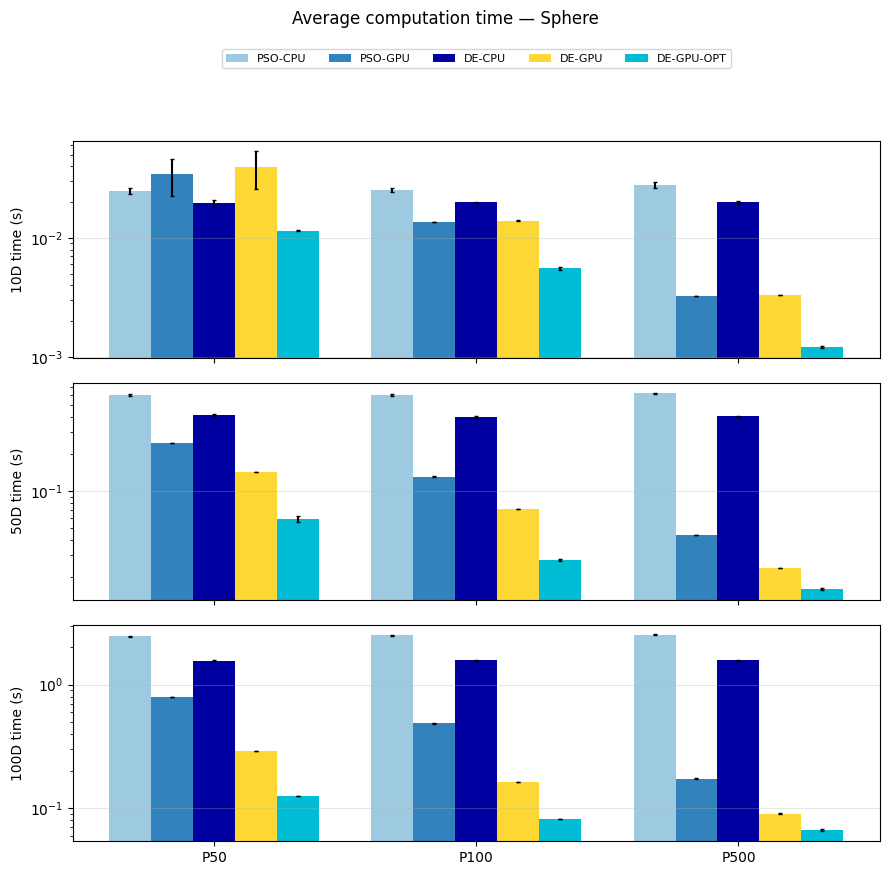

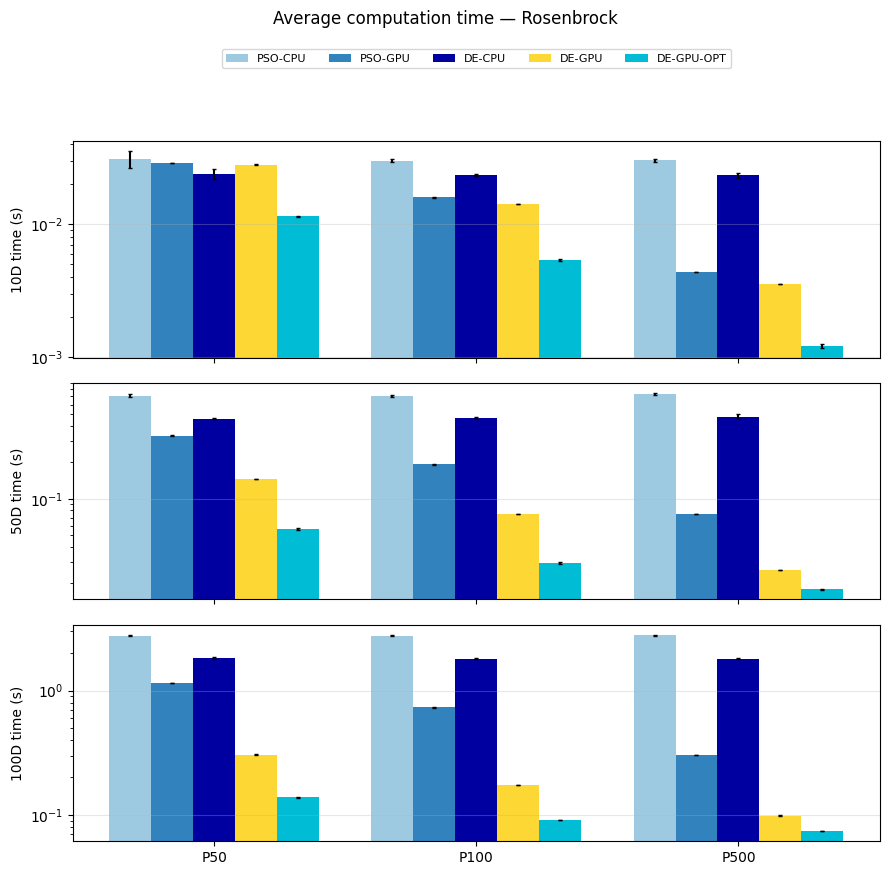

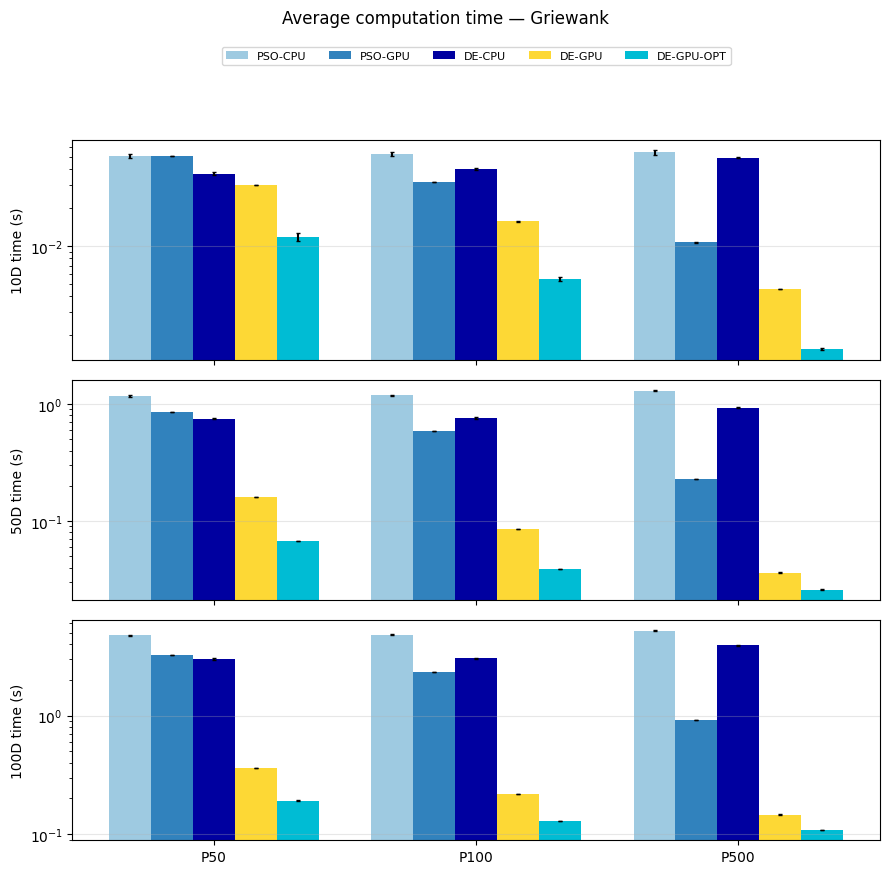

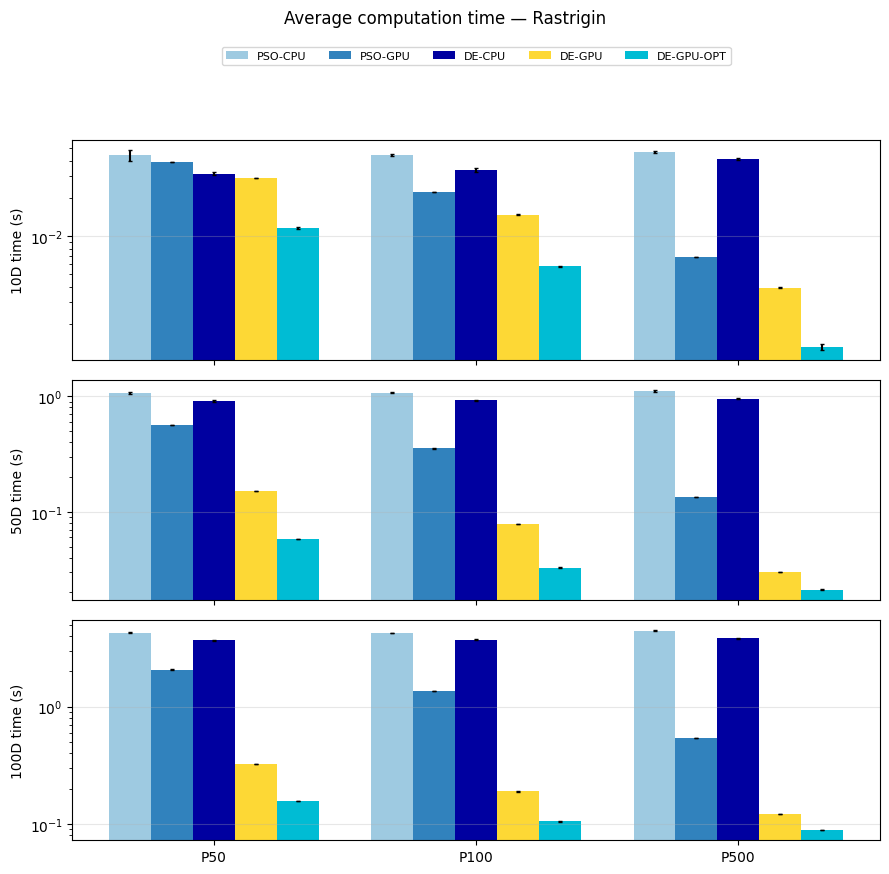

In [17]:
LOG = True            # CPU vs GPU times differ by orders of magnitude; set False for the linear scale of the article
COL = {'PSO-CPU': '#9ecae1', 'PSO-GPU': '#3182bd', 'DE-CPU': '#0000a0', 'DE-GPU': '#fdd835', 'DE-GPU-OPT': '#00bcd4'}
def fig_time(fn):
    fig, axs = plt.subplots(len(DIM), 1, figsize=(9, 2.9 * len(DIM)), sharex=True)
    axs = np.atleast_1d(axs); w = 0.8 / len(ALG)
    for ax, dim in zip(axs, DIM):
        for k, a in enumerate(ALG):
            m = [df[(df.algo == a) & (df.func == fn) & (df.dim == dim) & (df['pop'] == p)].time_s.mean() for p in POP]
            s = [df[(df.algo == a) & (df.func == fn) & (df.dim == dim) & (df['pop'] == p)].time_s.std(ddof=1) for p in POP]
            ax.bar(np.arange(len(POP)) + k * w - 0.4 + w / 2, m, w, yerr=np.nan_to_num(s), label=a, color=COL[a], capsize=1.5)
        ax.set_ylabel(f'{dim}D time (s)'); ax.grid(axis='y', alpha=.3)
        if LOG: ax.set_yscale('log')
    axs[-1].set_xticks(range(len(POP))); axs[-1].set_xticklabels([f'P{p}' for p in POP])
    axs[0].legend(ncol=len(ALG), fontsize=8, loc='upper center', bbox_to_anchor=(.5, 1.45))
    fig.suptitle(f'Average computation time — {fn}', y=1.0 if len(DIM) > 1 else 1.08)
    fig.tight_layout(); return fig
for i, fn in enumerate(FUN):
    f = fig_time(fn); f.savefig(os.path.join(WORK, f'fig_time_{i+3}_{fn}.png'), dpi=200, bbox_inches='tight'); plt.show()

## 7. Speedups (mean time ratios)

PSO-GPU vs PSO-CPU  DE-GPU vs DE-CPU  DE-GPU-OPT vs DE-CPU  DE-GPU-OPT vs DE-GPU
dim pop                                                                                  
10  50                 0.99              0.91                  2.41                  2.75
    100                1.84              1.97                  5.25                  2.64
    500                6.87              8.50                 24.77                  2.90
50  50                 1.96              4.18                 10.52                  2.51
    100                3.31              8.12                 19.45                  2.43
    500                9.41             23.28                 33.16                  1.43
100 50                 2.26              7.73                 16.16                  2.12
    100                3.53             13.43                 24.53                  1.85
    500                9.40             23.59                 31.86                  1.35

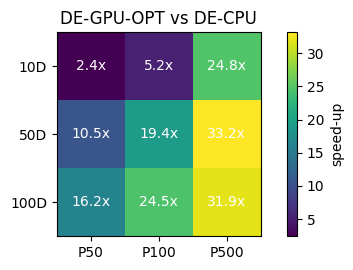

In [18]:
T = df.groupby(['algo', 'func', 'dim', 'pop']).time_s.mean().unstack('algo')
def speedup(num, den): return (T[num] / T[den]) if num in T and den in T else None
SP = pd.DataFrame({k: v for k, v in {
    'PSO-GPU vs PSO-CPU':    speedup('PSO-CPU', 'PSO-GPU'),
    'DE-GPU vs DE-CPU':      speedup('DE-CPU', 'DE-GPU'),
    'DE-GPU-OPT vs DE-CPU':  speedup('DE-CPU', 'DE-GPU-OPT'),
    'DE-GPU-OPT vs DE-GPU':  speedup('DE-GPU', 'DE-GPU-OPT'),
}.items() if v is not None})
SP.round(2).to_csv(os.path.join(WORK, 'speedups.csv'))
display(SP.groupby(['dim', 'pop']).mean().round(2))      # mean over the 4 functions
# heat map : speed-up of DE-GPU-OPT over DE-CPU
if 'DE-GPU-OPT vs DE-CPU' in SP:
    H = SP['DE-GPU-OPT vs DE-CPU'].groupby(['dim', 'pop']).mean().unstack('pop')
    plt.figure(figsize=(5.5, 2.8)); plt.imshow(H.values, cmap='viridis'); plt.colorbar(label='speed-up')
    plt.xticks(range(len(H.columns)), [f'P{c}' for c in H.columns]); plt.yticks(range(len(H.index)), [f'{i}D' for i in H.index])
    for i in range(H.shape[0]):
        for j in range(H.shape[1]): plt.text(j, i, f'{H.values[i,j]:.1f}x', ha='center', va='center', color='w')
    plt.title('DE-GPU-OPT vs DE-CPU'); plt.tight_layout(); plt.savefig(os.path.join(WORK, 'fig_speedup_heatmap.png'), dpi=200); plt.show()

## 8. Solution quality: mean EFV per algorithm (log scale) and success rates

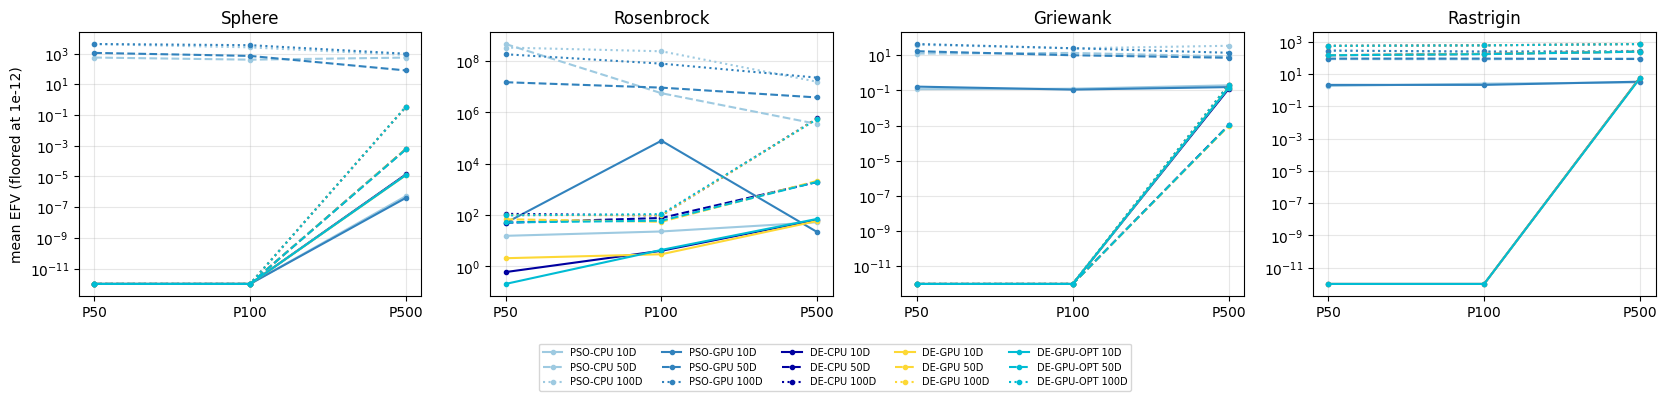

algo                PSO-CPU  PSO-GPU  DE-CPU  DE-GPU  DE-GPU-OPT
func       dim pop                                              
Griewank   10  50       0.0      0.0     1.0     1.0         1.0
               100      0.0      0.0     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0
           50  50       0.0      0.0     1.0     1.0         1.0
               100      0.0      0.0     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0
           100 50       0.0      0.0     1.0     1.0         1.0
               100      0.0      0.0     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0
Rastrigin  10  50       0.1      0.0     1.0     1.0         1.0
               100      0.2      0.1     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0
           50  50       0.0      0.0     0.0     0.0         0.0
               100      0.0      0.0     0.0     0.0         0.0
               500      0.0      0.0     0.0     0.0         0.0
           100 50       0.0      0.0     0.0     0.0         0.0
               100      0.0      0.0     0.0     0.0         0.0
               500      0.0      0.0     0.0     0.0         0.0
Rosenbrock 10  50       0.0      0.0     0.0     0.0         0.0
               100      0.0      0.0     0.0     0.0         0.0
               500      0.0      0.0     0.0     0.0         0.0
           50  50       0.0      0.0     0.0     0.0         0.0
               100      0.0      0.0     0.0     0.0         0.0
               500      0.0      0.0     0.0     0.0         0.0
           100 50       0.0      0.0     0.0     0.0         0.0
               100      0.0      0.0     0.0     0.0         0.0
               500      0.0      0.0     0.0     0.0         0.0
Sphere     10  50       1.0      1.0     1.0     1.0         1.0
               100      1.0      1.0     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0
           50  50       0.0      0.0     1.0     1.0         1.0
               100      0.1      0.0     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0
           100 50       0.0      0.0     1.0     1.0         1.0
               100      0.0      0.0     1.0     1.0         1.0
               500      0.0      0.0     0.0     0.0         0.0

In [19]:
fig, axs = plt.subplots(1, len(FUN), figsize=(4.2 * len(FUN), 3.4), squeeze=False)
for ax, fn in zip(axs[0], FUN):
    for a in ALG:
        for dim, ls in zip(DIM, ['-', '--', ':']):
            y = [df[(df.algo == a) & (df.func == fn) & (df.dim == dim) & (df['pop'] == p)].error.mean() for p in POP]
            ax.plot(range(len(POP)), np.maximum(y, 1e-12), ls, marker='o', ms=3, color=COL[a], label=f'{a} {dim}D' if fn == FUN[0] else None)
    ax.set_yscale('log'); ax.set_xticks(range(len(POP))); ax.set_xticklabels([f'P{p}' for p in POP]); ax.set_title(fn); ax.grid(alpha=.3)
axs[0][0].set_ylabel('mean EFV (floored at 1e-12)')
fig.legend(*axs[0][0].get_legend_handles_labels(), loc='lower center', ncol=5, fontsize=7, bbox_to_anchor=(.5, -0.18))
fig.tight_layout(); fig.savefig(os.path.join(WORK, 'fig_quality.png'), dpi=200, bbox_inches='tight'); plt.show()
SR = df.groupby(['algo', 'func', 'dim', 'pop']).success.mean().unstack('algo')[ALG]; display(SR.round(2))

## 9. Statistical tests (required by the subject)
Wilcoxon signed-rank (paired by seed: run *k* uses the same seed for every algorithm) and Kruskal–Wallis on the final EFV.

In [20]:
from scipy import stats
def wilcoxon_p(x, y):
    d = np.asarray(x) - np.asarray(y)
    if np.allclose(d, 0): return 1.0
    try: return stats.wilcoxon(x, y).pvalue
    except Exception: return np.nan
PAIRS = [('DE-GPU-OPT', 'DE-CPU'), ('DE-GPU-OPT', 'DE-GPU'), ('DE-GPU-OPT', 'PSO-GPU'), ('DE-CPU', 'PSO-CPU')]
rows = []
for fn in FUN:
    for dim in DIM:
        for p in POP:
            s = df[(df.func == fn) & (df.dim == dim) & (df['pop'] == p)]
            r = {'func': fn, 'dim': dim, 'pop': p}
            piv = s.pivot_table(index='run', columns='algo', values='error')
            for a, b in PAIRS:
                if a in piv and b in piv:
                    z = piv[[a, b]].dropna()
                    r[f'W {a}|{b}'] = wilcoxon_p(z[a], z[b]) if len(z) >= 2 else np.nan
            groups = [g.error.values for _, g in s.groupby('algo') if len(g) > 1]
            try: r['Kruskal'] = stats.kruskal(*groups).pvalue if len(groups) > 1 else np.nan
            except Exception: r['Kruskal'] = 1.0
            rows.append(r)
ST = pd.DataFrame(rows); ST.to_csv(os.path.join(WORK, 'stat_tests.csv'), index=False)
def hl(v): return 'background-color:#c8e6c9' if isinstance(v, float) and v < 0.05 else ''
ST.style.format({c: '{:.3g}' for c in ST.columns[3:]}).map(hl, subset=ST.columns[3:])

,func,dim,pop,W DE-GPU-OPT|DE-CPU,W DE-GPU-OPT|DE-GPU,W DE-GPU-OPT|PSO-GPU,W DE-CPU|PSO-CPU,Kruskal
0,Sphere,10,50,1,1,1,1,1
1,Sphere,10,100,1,1,1,1,1
2,Sphere,10,500,0.492,0.432,0.00195,0.00195,3.21e-07
3,Sphere,50,50,1,1,0.00195,0.00195,3.89e-09
4,Sphere,50,100,1,1,0.00195,0.00195,3.02e-09
5,Sphere,50,500,0.084,0.16,0.00195,0.00195,2.95e-07
6,Sphere,100,50,1,1,0.00195,0.00195,1.76e-08
7,Sphere,100,100,1,1,0.00195,0.00195,3.96e-09
8,Sphere,100,500,0.846,1,0.00195,0.00195,3.93e-07
9,Rosenbrock,10,50,0.193,0.00586,0.00391,0.00195,6.38e-06


**Reading the tests**: p < 0.05 (green) = significant difference at 5%. With 10 runs Wilcoxon can reach p ≈ 0.002; with the 3 runs of QUICK it cannot go below ≈ 0.25, so only draw conclusions from the 10-run protocol.  
Note: EFV is about the *solution*, the GPU/CPU variants of the same algorithm only differ by their RNG — so no significant difference is expected for them; the interesting EFV comparison is DE vs PSO. For *time*, differences are systematic.

## 10. Export

In [22]:
import zipfile
OUT = os.path.join(WORK, 'results_pack.zip')
with zipfile.ZipFile(OUT, 'w') as z:
    for f in glob.glob(os.path.join(WORK, '*.png')) + glob.glob(os.path.join(WORK, '*.csv')): z.write(f, os.path.basename(f))
print(OUT, os.path.getsize(OUT) // 1024, 'KB')
if ON_COLAB:
    from google.colab import files; files.download(OUT)

/kaggle/working/cudade/results_pack.zip 739 KB
